# Credit Scoring — моделирование

В этом ноутбуке:

1. Загружаем подготовленные признаки.
2. Разделяем данные на train и validation.
3. Строим baseline.
4. Проверяем ROC-AUC.
5. Улучшаем модель.
6. Обучаем финальную модель и создаём submission.

# 1. Импорты и настройки

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd 

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:.4f}".format)

RANDOM_STATE = 42

DATA_PATH = Path.home() / "projects" / "Credit_scoring" / "processed"

# 2. Загрузка данных

In [5]:
train_path = DATA_PATH / "train_features.csv"
test_path = DATA_PATH / "test_features.csv"

train_features = pd.read_csv(train_path)
test_features = pd.read_csv(test_path)

print("Train shape:", train_features.shape)
print("Test shape:", test_features.shape)

Train shape: (307511, 228)
Test shape: (48744, 227)


# 3. Проверка структуры

In [6]:
print("TARGET есть в train:", "TARGET" in train_features.columns)
print("TARGET есть в test:", "TARGET" in test_features.columns)

print(
    "Дубликатов SK_ID_CURR в train:",
    train_features["SK_ID_CURR"].duplicated().sum(),
)

print(
    "Дубликатов SK_ID_CURR в test:",
    test_features["SK_ID_CURR"].duplicated().sum(),
)

train_feature_columns = set(train_features.columns) - {"TARGET"}
test_feature_columns = set(test_features.columns)

print(
    "Признаки train и test совпадают:",
    train_feature_columns == test_feature_columns,
)

TARGET есть в train: True
TARGET есть в test: False
Дубликатов SK_ID_CURR в train: 0
Дубликатов SK_ID_CURR в test: 0
Признаки train и test совпадают: True


# 4. Проверим баланс классов

In [7]:
target_counts = train_features["TARGET"].value_counts()
target_percent = train_features["TARGET"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "COUNT": target_counts,
    "PERCENT": target_percent,
})

display(target_summary)

,COUNT,PERCENT
TARGET,,
0,282686,91.9271
1,24825,8.0729


## Вывод

Мы видим дисбаланс классов, при самой тупой модели константе с 0, можем получить 92% accuracy, основной метрикой будем использовать `ROC-AUC`

# 5. Начинаем делать модели

In [8]:
from sklearn.model_selection import train_test_split

TARGET_COLUMN = "TARGET"
ID_COLUMN = "SK_ID_CURR"

X = train_features.drop(
    columns = [TARGET_COLUMN, ID_COLUMN]        # удаляем целевую переменную и ID
)

y = train_features[TARGET_COLUMN]

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = RANDOM_STATE,
    stratify = y,
)


In [9]:
# Проверим

print("X shape:", X.shape)
print("y shape:", y.shape)

print("X_train shape:", X_train.shape)
print("X_valid shape:", X_valid.shape)

print("\nДоля TARGET = 1:")
print("Полные данные:", y.mean())
print("Train:", y_train.mean())
print("Validation:", y_valid.mean())

X shape: (307511, 226)
y shape: (307511,)
X_train shape: (246008, 226)
X_valid shape: (61503, 226)

Доля TARGET = 1:
Полные данные: 0.08072881945686496
Train: 0.08072908198107379
Validation: 0.08072776937710356


In [10]:
numeric_columns = X_train.select_dtypes(
    include = ["number"]
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    include = ["object", "category", "bool"]
).columns.tolist()

print("Числовых признаков:", len(numeric_columns))

print("Категориальных признаков:", len(categorical_columns))

Числовых признаков: 210
Категориальных признаков: 16


/var/folders/js/7__3y9xx3zl19t16cmcp0wmh0000gn/T/ipykernel_63035/642853585.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


In [11]:
print("\nПервые числовые признаки:")
print(numeric_columns[:10])

print("\nПервые категориальные признаки:")
print(categorical_columns[:10])


Первые числовые признаки:
['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH']

Первые категориальные признаки:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']


In [12]:
all_selected_columns = set(
    numeric_columns + categorical_columns
)

missing_columns = set(X_train.columns) - all_selected_columns

print("Не распределённые столбцы:", missing_columns)

Не распределённые столбцы: set()


In [13]:
# Проверим категориальные признаки

categorical_summary = pd.DataFrame({
    "COLUMN": categorical_columns,
    "UNIQUE_VALUES": [
        X_train[column].nunique(dropna=False)
        for column in categorical_columns
    ],
    "MISSING_PERCENT": [
        X_train[column].isna().mean() * 100
        for column in categorical_columns
    ],
})

display(
    categorical_summary.sort_values(
        "UNIQUE_VALUES",
        ascending=False,
    )
)

,COLUMN,UNIQUE_VALUES,MISSING_PERCENT
11,ORGANIZATION_TYPE,58,0.0000
9,OCCUPATION_TYPE,19,31.2754
4,NAME_TYPE_SUITE,8,0.4183
5,NAME_INCOME_TYPE,8,0.0000
14,WALLSMATERIAL_MODE,8,50.8012
10,WEEKDAY_APPR_PROCESS_START,7,0.0000
7,NAME_FAMILY_STATUS,6,0.0000
8,NAME_HOUSING_TYPE,6,0.0000
6,NAME_EDUCATION_TYPE,5,0.0000
12,FONDKAPREMONT_MODE,5,68.3779


## Краткий вывод по категориям

* Большинство категориальных признаков имеют мало уникальных значений, поэтому для baseline подойдёт OneHotEncoder.
* `ORGANIZATION_TYPE` содержит 58 категорий, поэтому для него используем частотное кодирование вместо OneHotEncoder.
* Самые большие пропуски:
    * FONDKAPREMONT_MODE — около 68%;
    * WALLSMATERIAL_MODE — около 51%;
    * HOUSETYPE_MODE — около 50%;
    * EMERGENCYSTATE_MODE — около 47%;
    * OCCUPATION_TYPE — около 31%.
* Эти признаки пока не удаляем. Пропуск может сам быть полезным сигналом, например отсутствие данных о жилье или профессии.


# 6. Делаем Pipeline предобработки

In [14]:
# Для ORGANIZATION_TYPE используем частотное кодирование
# Частоты считаем только по train, чтобы не допустить утечку данных

organization_frequency = (
    X_train["ORGANIZATION_TYPE"]
    .fillna("Missing")
    .value_counts(normalize=True)
)

X_train = X_train.copy()
X_valid = X_valid.copy()

X_train["ORGANIZATION_TYPE_FREQ"] = (
    X_train["ORGANIZATION_TYPE"]
    .fillna("Missing")
    .map(organization_frequency)
)

X_valid["ORGANIZATION_TYPE_FREQ"] = (
    X_valid["ORGANIZATION_TYPE"]
    .fillna("Missing")
    .map(organization_frequency)
    .fillna(0)
)

X_train = X_train.drop(columns=["ORGANIZATION_TYPE"])
X_valid = X_valid.drop(columns=["ORGANIZATION_TYPE"])

# После изменения заново определяем числовые и категориальные признаки
numeric_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("ORGANIZATION_TYPE остался:", "ORGANIZATION_TYPE" in X_train.columns)
print("ORGANIZATION_TYPE_FREQ создан:", "ORGANIZATION_TYPE_FREQ" in X_train.columns)


ORGANIZATION_TYPE остался: False
ORGANIZATION_TYPE_FREQ создан: True


/var/folders/js/7__3y9xx3zl19t16cmcp0wmh0000gn/T/ipykernel_63035/2317772786.py:34: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median"),
        ),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing",  # Отдельная категория Missing
            ),
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",  # Неизвестные категории не вызывают ошибку
                sparse_output=True,
            ),
        ),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_columns,
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_columns,
        ),
    ]
)


# 7. Обучим первую модель Logistic Regression

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

baseline_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor,
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

baseline_model.fit(
    X_train,
    y_train,
)

valid_probabilities = baseline_model.predict_proba(
    X_valid
)[:, 1]

baseline_roc_auc = roc_auc_score(
    y_valid,
    valid_probabilities,
)

print(
    f"Baseline ROC-AUC: {baseline_roc_auc:.4f}"
)

/Users/kheichiev/projects/Credit_scoring/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Baseline ROC-AUC: 0.6451


## 7.1 Посмотрим на Roc и PR кривые 

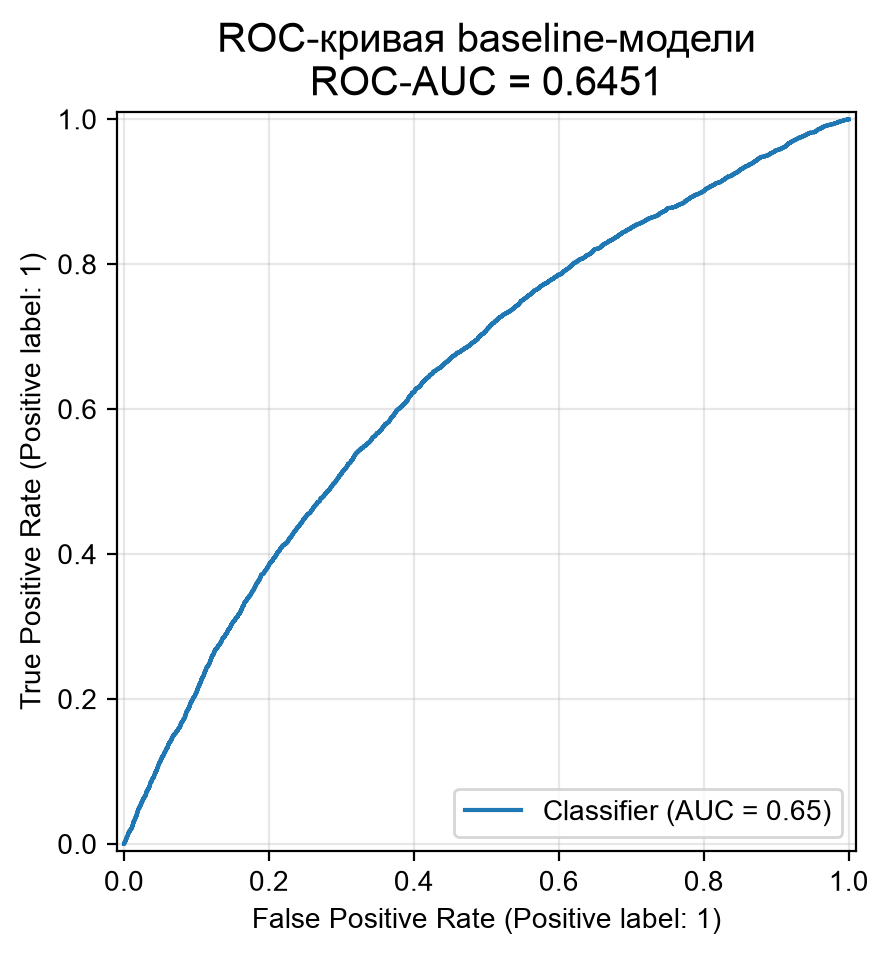

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay,
    average_precision_score,
)

RocCurveDisplay.from_predictions(
    y_valid,
    valid_probabilities,
)

%config InlineBackend.figure_format = 'retina'
plt.rcParams['figure.figsize'] = 8, 5
plt.rcParams['font.size'] = 12
sns.set_style('darkgrid')
plt.rcParams['savefig.format'] = 'pdf'

plt.title(
    f"ROC-кривая baseline-модели\nROC-AUC = {baseline_roc_auc:.4f}"
)
plt.grid(alpha=0.3)
plt.show()


### Вывод по ROC-кривой 
Модель ранжирует клиентов лучше случайного классификатора, но разделение классов остается умеренным, Roc-кривая почти прямая :)

Берем эту модель как отправную точку

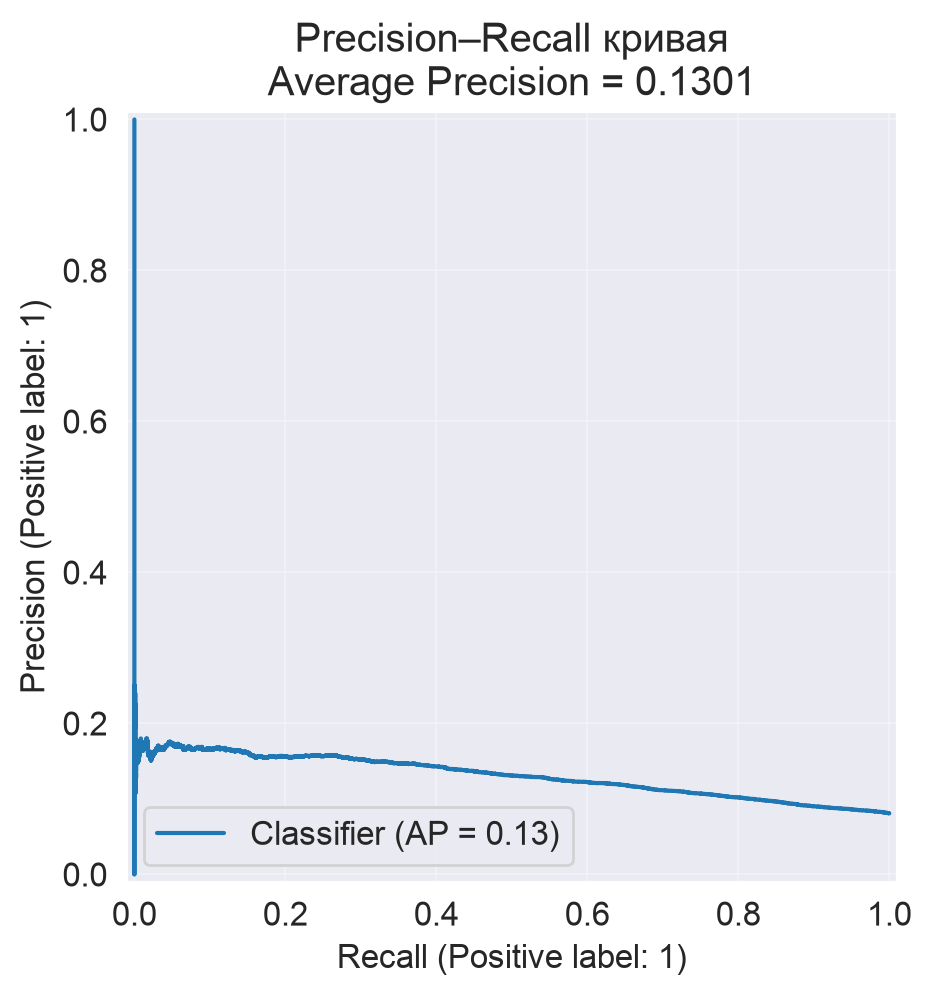

In [18]:
average_precision = average_precision_score(
    y_valid,
    valid_probabilities,
)

PrecisionRecallDisplay.from_predictions(
    y_valid,
    valid_probabilities,
)

plt.title(
    "Precision–Recall кривая\n"
    f"Average Precision = {average_precision:.4f}"
)
plt.grid(alpha=0.3)
plt.show()

### Вывод по PR кривой

Увеличение Recall привод к снижению precision, логично

In [19]:
positive_class_rate = y_valid.mean()

print(
    f"Доля TARGET = 1: {positive_class_rate:.4f}"
)

print(
    f"Average Precision модели: {average_precision:.4f}"
)

print(
    "Улучшение относительно случайного baseline:",
    f"{average_precision / positive_class_rate:.2f} раза",
)

Доля TARGET = 1: 0.0807
Average Precision модели: 0.1301
Улучшение относительно случайного baseline: 1.61 раза


### Вывод

Baseline-модель показывает ROC-AUC 0.6451 и ранжирует клиентов лучше случайного классификатора, однако разделение классов остаётся умеренным.

Precision–Recall кривая показывает выраженный компромисс между полнотой обнаружения проблемных клиентов и точностью таких предсказаний. При увеличении recall модель находит больше клиентов с TARGET = 1, но одновременно увеличивается количество ложных срабатываний.

Поэтому порог классификации нельзя выбирать автоматически равным 0.5: его необходимо подбирать под бизнес-стоимость ложного одобрения и ложного отказа.

## 7.2 Построим графики зависимостей, чтобы подобрать порог

* F1-score;
* precision;
* recall

In [20]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
)

thresholds = np.arange(0.05, 0.81, 0.01)

f1_scores = []
precision_scores = []
recall_scores = []

for threshold in thresholds:
    valid_predictions = (
        valid_probabilities >= threshold
    ).astype(int)

    f1_scores.append(
        f1_score(y_valid, valid_predictions)
    )

    precision_scores.append(
        precision_score(
            y_valid,
            valid_predictions,
            zero_division=0,
        )
    )

    recall_scores.append(
        recall_score(
            y_valid,
            valid_predictions,
            zero_division=0,
        )
    )

best_threshold_index = np.argmax(f1_scores)
best_threshold = thresholds[best_threshold_index]
best_f1 = f1_scores[best_threshold_index]

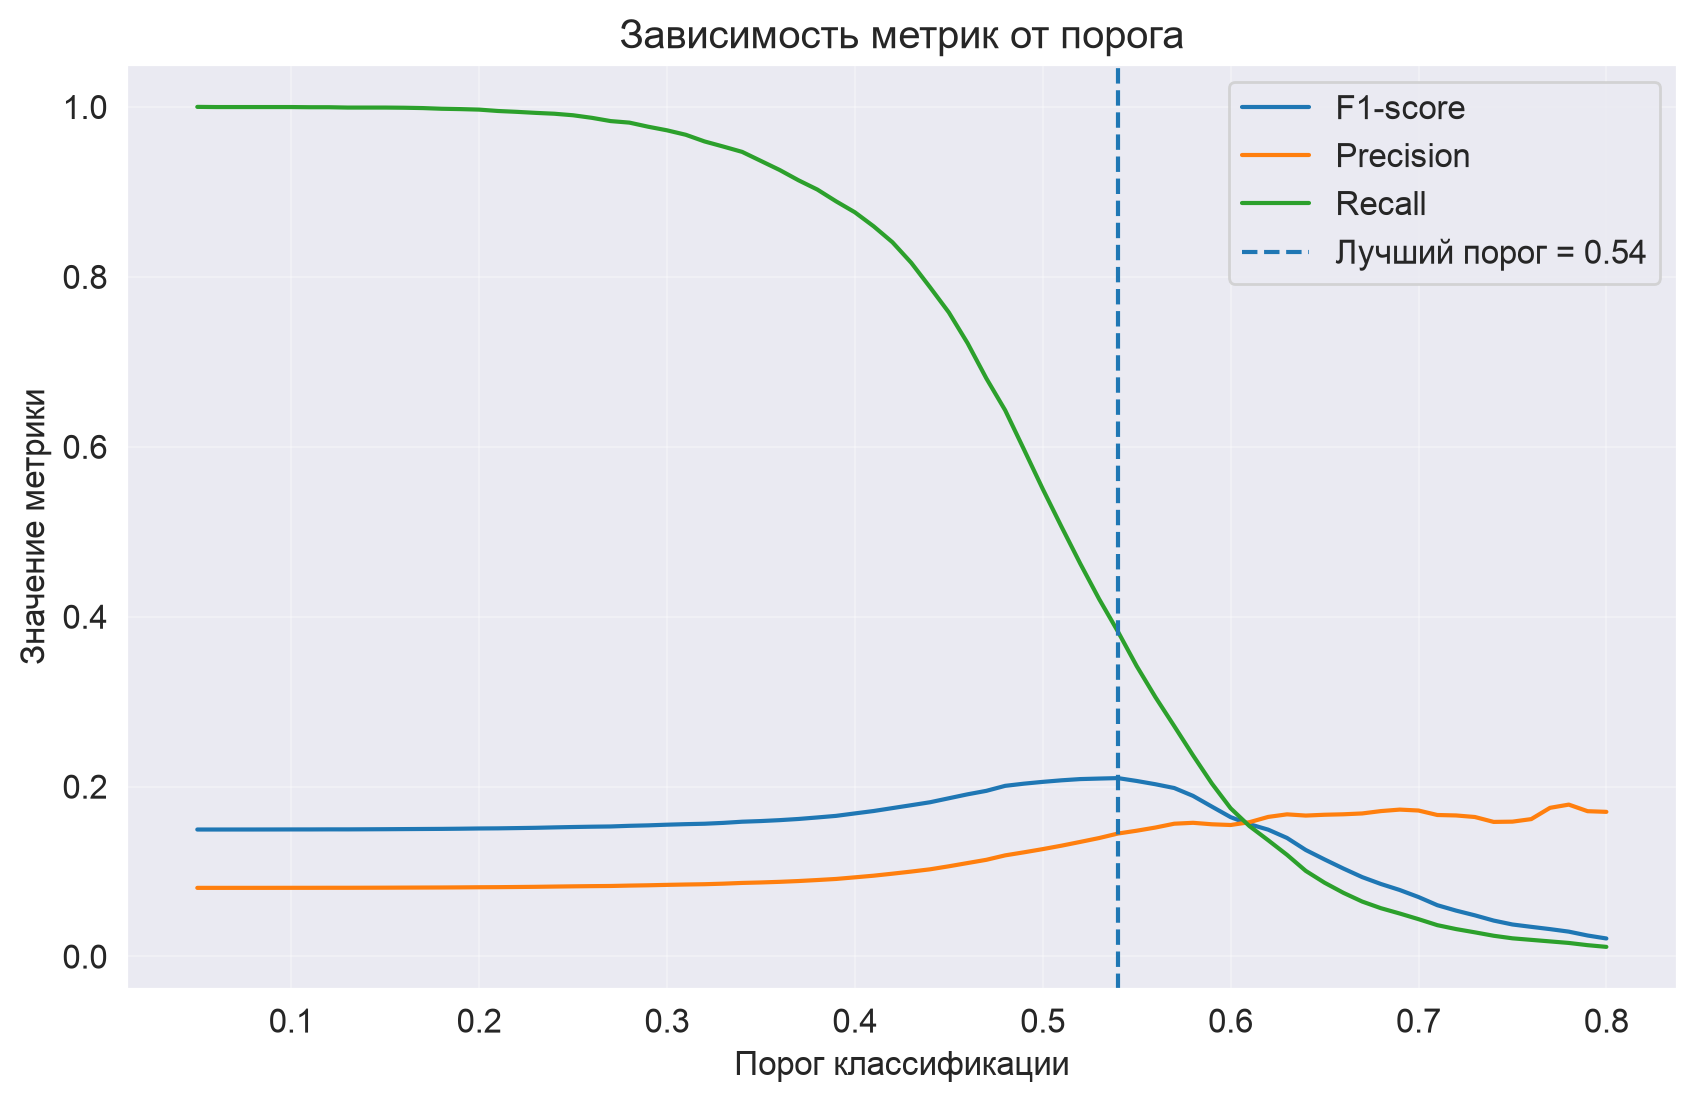

In [21]:
plt.figure(figsize=(10, 6))

plt.plot(
    thresholds,
    f1_scores,
    label="F1-score",
)

plt.plot(
    thresholds,
    precision_scores,
    label="Precision",
)

plt.plot(
    thresholds,
    recall_scores,
    label="Recall",
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=(
        f"Лучший порог = {best_threshold:.2f}"
    ),
)

plt.xlabel("Порог классификации")
plt.ylabel("Значение метрики")
plt.title("Зависимость метрик от порога")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Вывод
* Лучший порог по F1 получился около 0.54.
* Максимальный F1 — примерно 0.21, то есть модель пока слабо разделяет классы.
* При низких порогах recall почти равен 1, но precision очень низкий: модель помечает рискованными почти всех.
* При повышении порога precision немного растёт, но recall резко падает.
* В районе 0.54 достигается компромисс:
    * recall около 0.38;
    * precision около 0.15;
    * F1 около 0.21.


Модель лучше случайной, но пока даёт много ложных срабатываний и пропускает значительную часть проблемных клиентов.

## 7.3 Строим матрицу ошибок при пороге 0.54

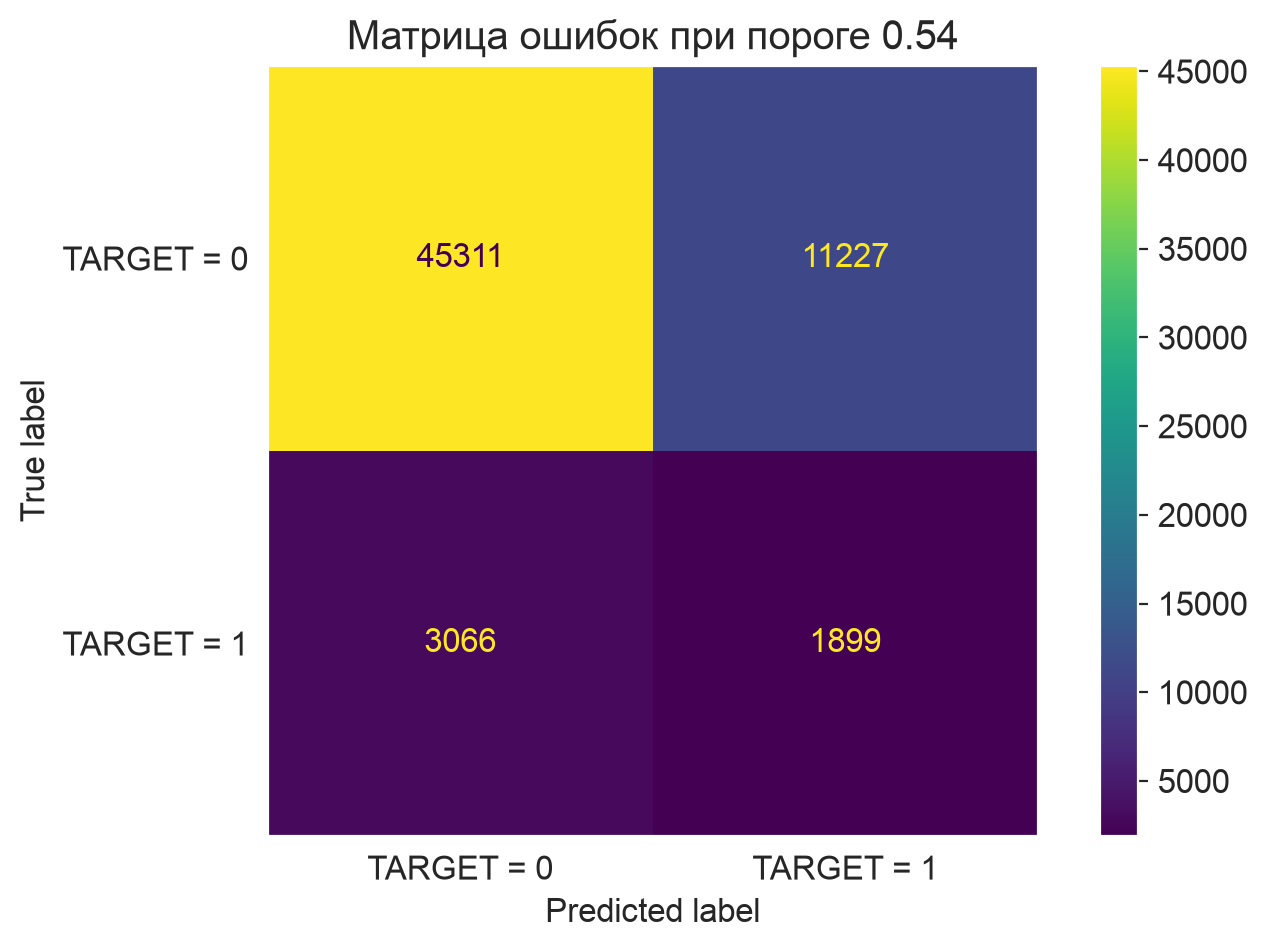

In [22]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    classification_report,
)

best_predictions = (
    valid_probabilities >= best_threshold
).astype(int)

confusion = confusion_matrix(
    y_valid,
    best_predictions,
)

display_confusion = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=[
        "TARGET = 0",
        "TARGET = 1",
    ],
)

display_confusion.plot(
    values_format="d",
)

plt.title(
    f"Матрица ошибок при пороге {best_threshold:.2f}"
)
plt.grid(False)
plt.show()

In [23]:
print(
    classification_report(
        y_valid,
        best_predictions,
        target_names=[
            "TARGET = 0",
            "TARGET = 1",
        ],
        digits=4,
        zero_division=0,
    )
)

              precision    recall  f1-score   support

  TARGET = 0     0.9366    0.8014    0.8638     56538
  TARGET = 1     0.1447    0.3825    0.2099      4965

    accuracy                         0.7676     61503
   macro avg     0.5406    0.5920    0.5369     61503
weighted avg     0.8727    0.7676    0.8110     61503



### Добавим нормированную матрицу

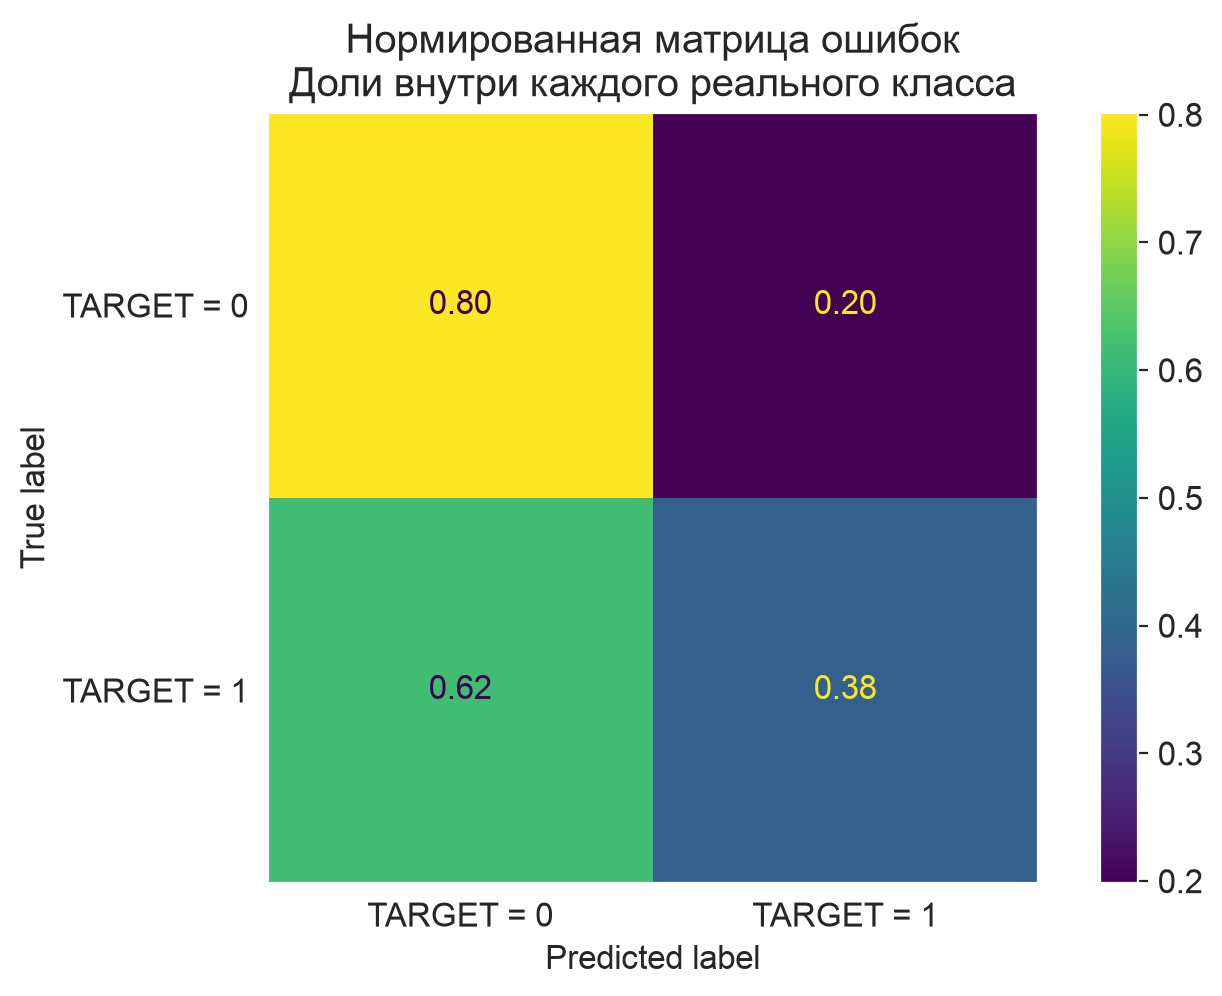

In [24]:
normalized_confusion = confusion_matrix(
    y_valid,
    best_predictions,
    normalize="true",
)

display_normalized = ConfusionMatrixDisplay(
    confusion_matrix=normalized_confusion,
    display_labels=[
        "TARGET = 0",
        "TARGET = 1",
    ],
)

display_normalized.plot(
    values_format=".2f",
)

plt.title(
    "Нормированная матрица ошибок\n"
    "Доли внутри каждого реального класса"
)
plt.grid(False)
plt.show()

## Вывод

При выбранном пороге модель сохраняет высокий результат по классу TARGET = 0, но значительно хуже распознаёт редкий класс TARGET = 1.

Низкий precision означает большое количество ложных срабатываний: среди клиентов, отмеченных моделью как рискованные, значительная часть фактически относится к TARGET = 0.

Низкий recall по TARGET = 1 означает, что модель пропускает часть проблемных клиентов. Для кредитного скоринга такие ошибки особенно важны, поэтому дальнейшее улучшение должно быть направлено не только на рост ROC-AUC, но и на повышение качества распознавания редкого класса.

## 7.4 Посмотрим как распределены вероятности

Если распределения сильно пересекаются, модель физически не может хорошо разделить классы одним порогом.

In [25]:
validation_predictions = pd.DataFrame({
    "TARGET": y_valid.to_numpy(),
    "PREDICTED_PROBABILITY": valid_probabilities,
})

target_0_probabilities = validation_predictions.loc[
    validation_predictions["TARGET"] == 0,
    "PREDICTED_PROBABILITY",
]

target_1_probabilities = validation_predictions.loc[
    validation_predictions["TARGET"] == 1,
    "PREDICTED_PROBABILITY",
]

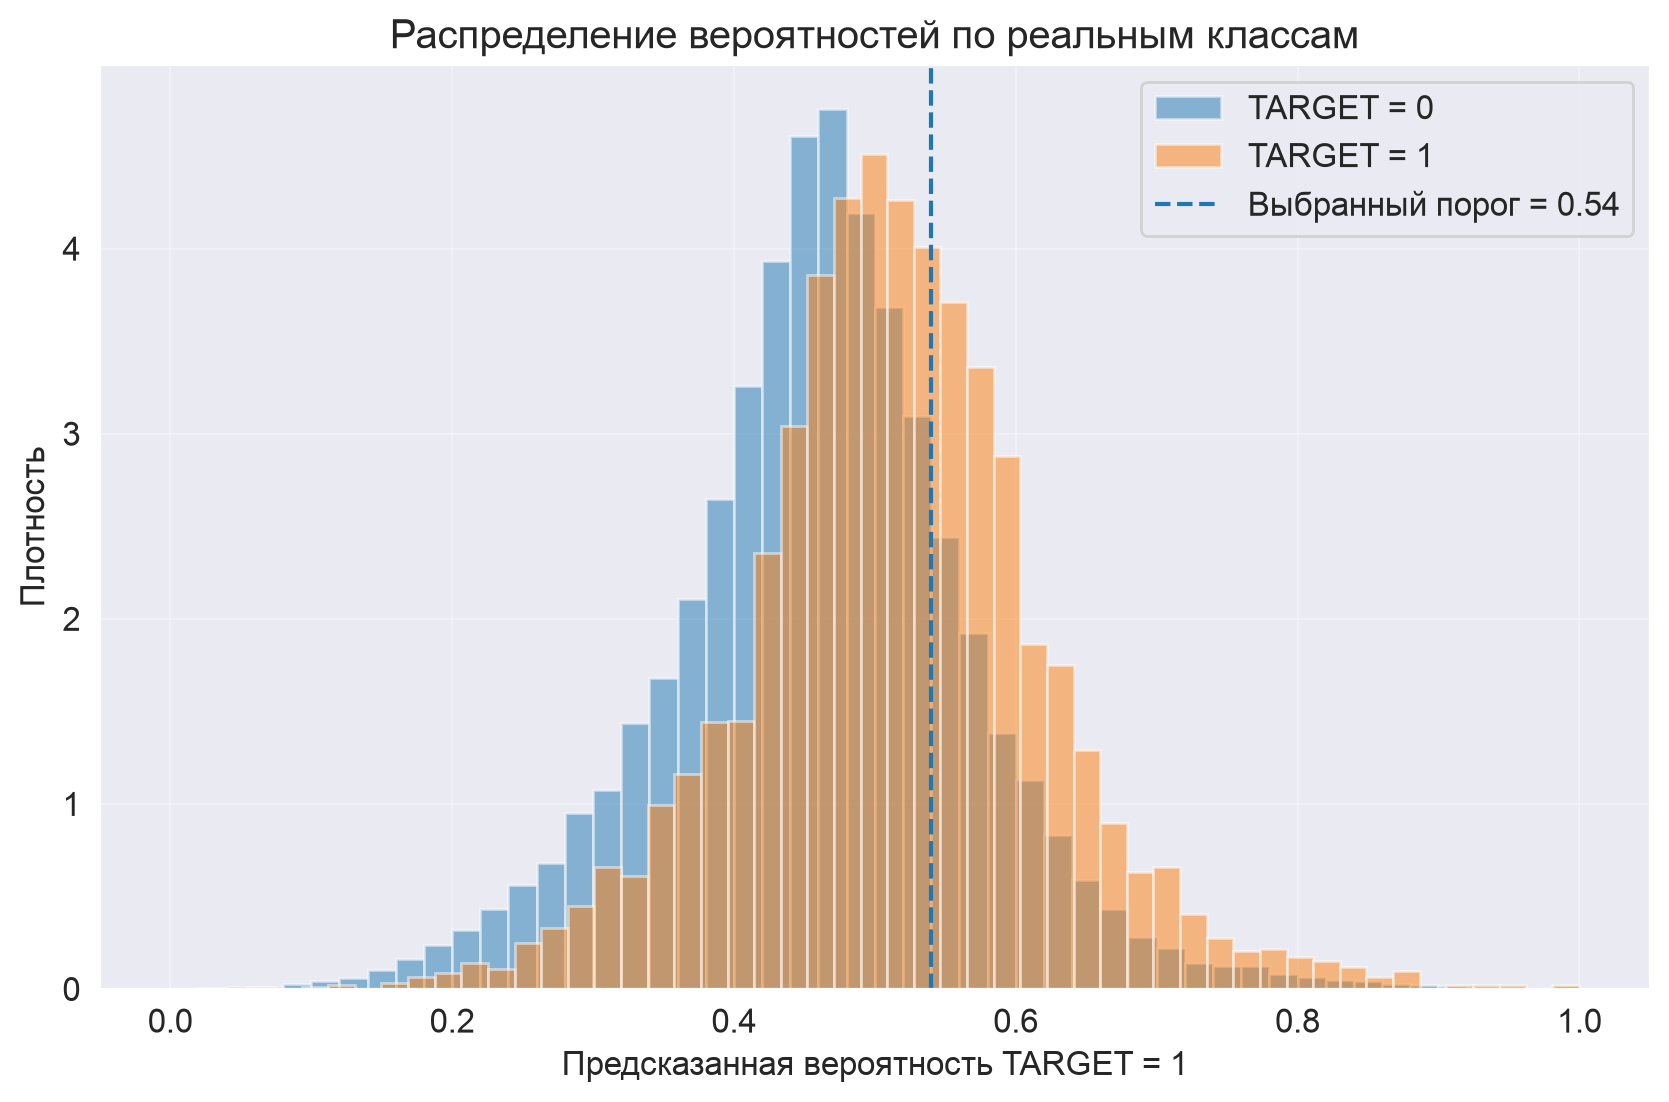

In [26]:
plt.figure(figsize=(10, 6))

plt.hist(
    target_0_probabilities,
    bins=50,
    density=True,
    alpha=0.5,
    label="TARGET = 0",
)

plt.hist(
    target_1_probabilities,
    bins=50,
    density=True,
    alpha=0.5,
    label="TARGET = 1",
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Выбранный порог = {best_threshold:.2f}",
)

plt.xlabel("Предсказанная вероятность TARGET = 1")
plt.ylabel("Плотность")
plt.title("Распределение вероятностей по реальным классам")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [27]:
probability_summary = (
    validation_predictions
    .groupby("TARGET")["PREDICTED_PROBABILITY"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max",
    )
)

display(probability_summary)

,count,mean,median,std,min,max
TARGET,,,,,,
0,56538,0.4606,0.4629,0.1079,0.0000,1.0000
1,4965,0.5134,0.5111,0.1070,0.0554,1.0000


Посмотрим квантили

In [28]:
probability_quantiles = (
    validation_predictions
    .groupby("TARGET")["PREDICTED_PROBABILITY"]
    .quantile([0.1, 0.25, 0.5, 0.75, 0.9])
    .unstack()
)

display(probability_quantiles)

,0.1000,0.2500,0.5000,0.7500,0.9000
TARGET,,,,,
0,0.3249,0.3997,0.4629,0.5232,0.5879
1,0.3816,0.4525,0.5111,0.5758,0.6403


### Вывод

Распределение вероятностей для клиентов с TARGET = 1 смещено в сторону более высоких значений, поэтому модель улавливает часть сигнала риска.

При этом распределения двух классов сильно пересекаются. Это означает, что проблема не сводится только к выбору порога: текущая модель и набор признаков пока не обеспечивают уверенного разделения клиентов.

Следовательно, дальнейшее улучшение должно быть направлено на усиление модели и признаков, а не только на настройку порога классификации.

# 8. Подготока данных для Catboost

In [29]:
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

X_train_cat = X_train.copy()
X_valid_cat = X_valid.copy()

categorical_columns_cat = X_train_cat.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

X_train_cat[categorical_columns_cat] = (
    X_train_cat[categorical_columns_cat]
    .fillna("Missing")
    .astype(str)
)

X_valid_cat[categorical_columns_cat] = (
    X_valid_cat[categorical_columns_cat]
    .fillna("Missing")
    .astype(str)
)

/var/folders/js/7__3y9xx3zl19t16cmcp0wmh0000gn/T/ipykernel_63035/2280770588.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns_cat = X_train_cat.select_dtypes(


## 8.1 Обучение CatBoost

In [30]:
catboost_model = CatBoostClassifier(
    iterations=500,     # максимум 500 деревьев.
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=RANDOM_STATE,
    verbose=100,
)

catboost_model.fit(
    X_train_cat,
    y_train,
    cat_features=categorical_columns_cat,
    eval_set=(X_valid_cat, y_valid),
    early_stopping_rounds=50,   #остановка, если качество 50 итераций не улучшается.
)

catboost_valid_proba = catboost_model.predict_proba(
    X_valid_cat
)[:, 1]

catboost_roc_auc = roc_auc_score(
    y_valid,
    catboost_valid_proba,
)

print(f"Logistic Regression ROC-AUC: {baseline_roc_auc:.4f}")
print(f"CatBoost ROC-AUC: {catboost_roc_auc:.4f}")

0:	test: 0.6387033	best: 0.6387033 (0)	total: 173ms	remaining: 1m 26s
100:	test: 0.7746416	best: 0.7746416 (100)	total: 9.91s	remaining: 39.2s
200:	test: 0.7817551	best: 0.7817551 (200)	total: 20.8s	remaining: 31s
300:	test: 0.7849004	best: 0.7849004 (300)	total: 31.6s	remaining: 20.9s
400:	test: 0.7865523	best: 0.7865523 (400)	total: 42.3s	remaining: 10.4s
499:	test: 0.7880763	best: 0.7880763 (499)	total: 53.2s	remaining: 0us

bestTest = 0.7880763348
bestIteration = 499

Logistic Regression ROC-AUC: 0.6451
CatBoost ROC-AUC: 0.7881


### Вывод:
CatBoost значительно лучше улавливает нелинейные зависимости и взаимодействия между признаками. Для этой табличной задачи он явно подходит лучше логистической регрессии. Также мы видим, что он дошел до 499, значит в будущем можем увеличить количество деревьев

## 8.2 Строим top-20 важностей признаков CatBoost

Это покажет, какие признаки сильнее всего влияли на решения модели. 

Смотрим, повышает он признак или снижает, является ли связь причинной.

In [31]:
feature_importance = pd.DataFrame({
    "FEATURE": X_train_cat.columns,
    "IMPORTANCE": catboost_model.get_feature_importance(),
})

feature_importance = feature_importance.sort_values(
    "IMPORTANCE",
    ascending=False,
)

display(feature_importance.head(20))

,FEATURE,IMPORTANCE
39,EXT_SOURCE_2,14.1488
40,EXT_SOURCE_3,12.8226
38,EXT_SOURCE_1,5.6723
133,BUREAU_MAX_DEBT_CREDIT_RATIO,3.5349
121,APP_CREDIT_ANNUITY_RATIO,3.2291
15,DAYS_BIRTH,2.8968
16,DAYS_EMPLOYED,2.6057
122,APP_GOODS_CREDIT_RATIO,2.3880
1,CODE_GENDER,2.2926
7,AMT_ANNUITY,1.9523


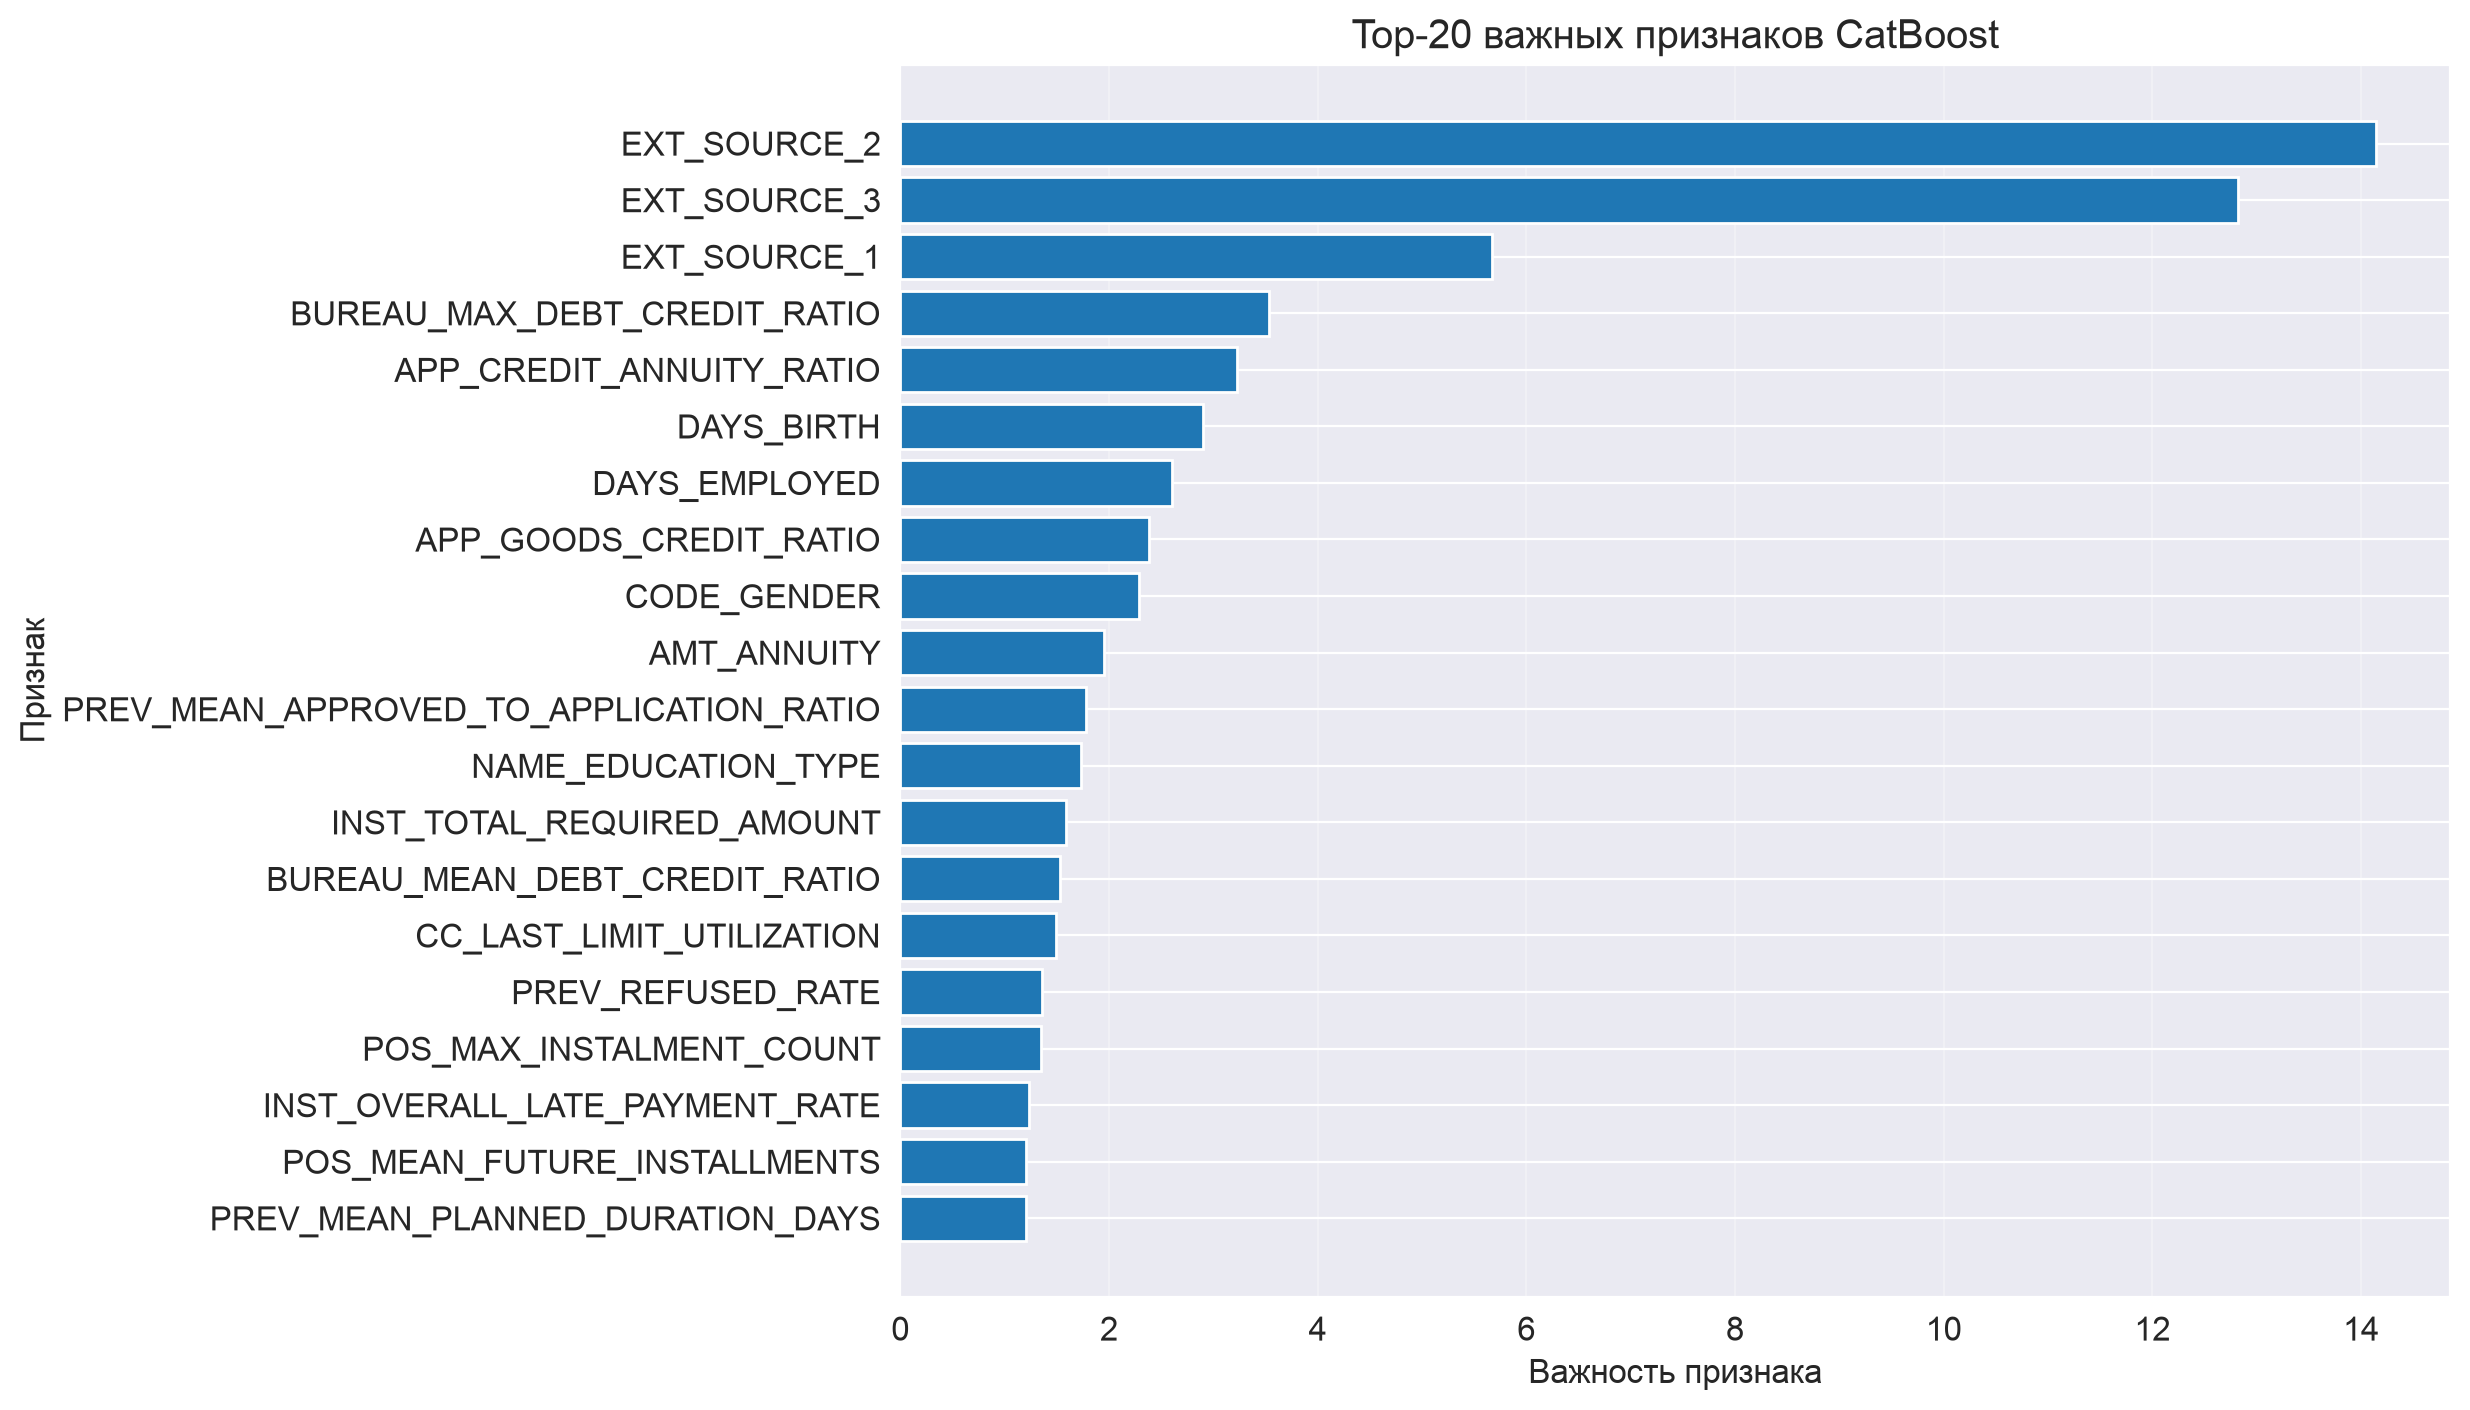

In [32]:
top_features = feature_importance.head(20).sort_values(
    "IMPORTANCE",
    ascending=True,
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["FEATURE"],
    top_features["IMPORTANCE"],
)

plt.xlabel("Важность признака")
plt.ylabel("Признак")
plt.title("Top-20 важных признаков CatBoost")
plt.grid(axis="x", alpha=0.3)
plt.show()

## Вывод
CatBoost сильнее всего опирается на внешние скоринговые признаки EXT_SOURCE_1, EXT_SOURCE_2 и EXT_SOURCE_3. Это означает, что готовые внешние оценки риска остаются главным источником сигнала. Также среди важных признаков были синтезированные в data_preprocessing, приятно

## 8.3 Попробуем улучшить CatBoost

In [33]:
catboost_model_1000 = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=RANDOM_STATE,
    verbose=100,
)

catboost_model_1000.fit(
    X_train_cat,
    y_train,
    cat_features=categorical_columns_cat,
    eval_set=(X_valid_cat, y_valid),
    early_stopping_rounds=100,
)

catboost_valid_proba_1000 = (
    catboost_model_1000
    .predict_proba(X_valid_cat)[:, 1]
)

catboost_roc_auc_1000 = roc_auc_score(
    y_valid,
    catboost_valid_proba_1000,
)

print(f"CatBoost 500 ROC-AUC: {catboost_roc_auc:.4f}")
print(f"CatBoost 1000 ROC-AUC: {catboost_roc_auc_1000:.4f}")
print(
    "Лучшая итерация:",
    catboost_model_1000.get_best_iteration(),
)

0:	test: 0.6387033	best: 0.6387033 (0)	total: 115ms	remaining: 1m 54s
100:	test: 0.7746416	best: 0.7746416 (100)	total: 10.8s	remaining: 1m 36s
200:	test: 0.7817551	best: 0.7817551 (200)	total: 21.8s	remaining: 1m 26s
300:	test: 0.7849004	best: 0.7849004 (300)	total: 32.8s	remaining: 1m 16s
400:	test: 0.7865523	best: 0.7865523 (400)	total: 43.8s	remaining: 1m 5s
500:	test: 0.7880774	best: 0.7880774 (500)	total: 54.7s	remaining: 54.5s
600:	test: 0.7889755	best: 0.7889770 (599)	total: 1m 6s	remaining: 43.8s
700:	test: 0.7897006	best: 0.7897006 (700)	total: 1m 17s	remaining: 33s
800:	test: 0.7903745	best: 0.7903745 (800)	total: 1m 29s	remaining: 22.1s
900:	test: 0.7905551	best: 0.7905703 (894)	total: 1m 41s	remaining: 11.1s
999:	test: 0.7909540	best: 0.7909660 (993)	total: 1m 53s	remaining: 0us

bestTest = 0.7909660417
bestIteration = 993

Shrink model to first 994 iterations.
CatBoost 500 ROC-AUC: 0.7881
CatBoost 1000 ROC-AUC: 0.7910
Лучшая итерация: 993


### Вывод
Ну логично, прирост небольшой, это было видно уже на 500 итарециях

# 9. Соберем результаты по baseline и CatBoost в 1 таблицу

In [34]:
model_results = pd.DataFrame(
    {
        "MODEL": [
            "Logistic Regression",
            "CatBoost 500",
            "CatBoost 1000",
        ],
        "ROC_AUC": [
            baseline_roc_auc,
            catboost_roc_auc,
            catboost_roc_auc_1000,
        ],
    }
)

model_results["IMPROVEMENT_VS_BASELINE"] = (
    model_results["ROC_AUC"]
    - baseline_roc_auc
)

display(
    model_results.sort_values(
        "ROC_AUC",
        ascending=False,
    )
)

,MODEL,ROC_AUC,IMPROVEMENT_VS_BASELINE
2,CatBoost 1000,0.7910,0.1458
1,CatBoost 500,0.7881,0.1429
0,Logistic Regression,0.6451,0.0000


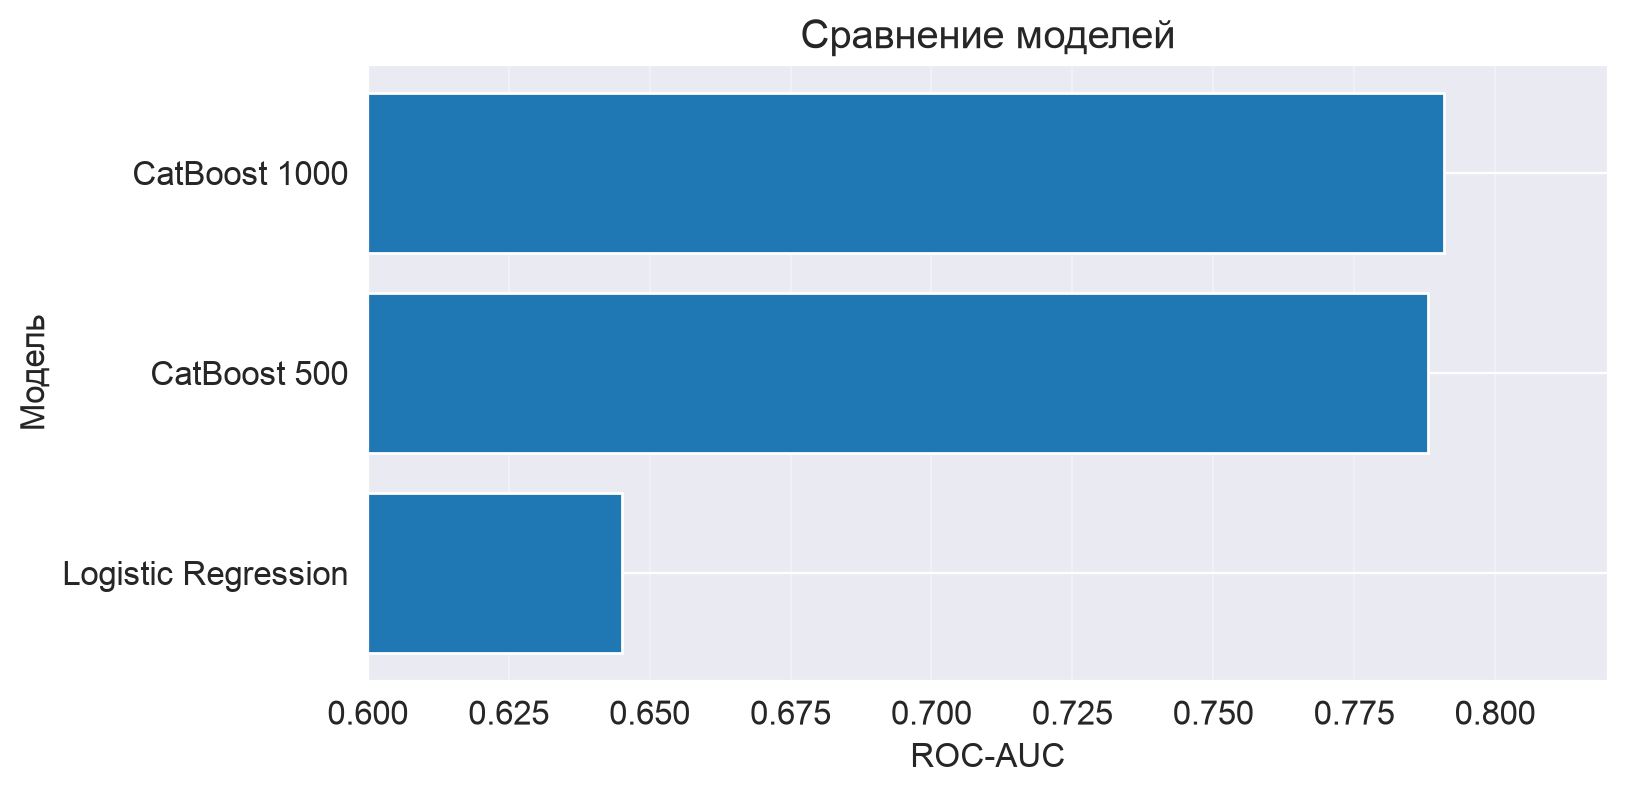

In [35]:
model_results_sorted = model_results.sort_values(
    "ROC_AUC",
    ascending=True,
)

plt.figure(figsize=(8, 4))

plt.barh(
    model_results_sorted["MODEL"],
    model_results_sorted["ROC_AUC"],
)

plt.xlabel("ROC-AUC")
plt.ylabel("Модель")
plt.title("Сравнение моделей")
plt.xlim(0.6, 0.82)
plt.grid(axis="x", alpha=0.3)
plt.show()

## Вывод

Логистическая регрессия показала ROC-AUC 0.6451 и использовалась как простой baseline.

CatBoost значительно улучшил качество до 0.7881 благодаря способности учитывать нелинейные зависимости и взаимодействия между признаками.

Увеличение числа итераций до 1000 дало дополнительный прирост до 0.7910. При этом улучшение оказалось небольшим, поэтому дальнейшее увеличение числа деревьев без изменения параметров вряд ли даст существенный результат.

## 10. Проверим также другие модели

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier,
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
)

tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_columns,
        ),
        (
            "categorical",
            Pipeline(
                steps=[
                    (
                        "imputer",
                        SimpleImputer(
                            strategy="constant",
                            fill_value="Missing",
                        ),
                    ),
                    (
                        "encoder",
                        OrdinalEncoder(
                            handle_unknown="use_encoded_value",
                            unknown_value=-1,
                        ),
                    ),
                ]
            ),
            categorical_columns,
        ),
    ]
)

In [39]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=50,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=20,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),

    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=31,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
}

tree_model_results = []
trained_tree_models = {}

for model_name, model in models.items():
    pipeline = Pipeline(
        steps=[
            ("preprocessor", tree_preprocessor),
            ("model", model),
        ]
    )

    pipeline.fit(X_train, y_train)

    valid_proba = pipeline.predict_proba(X_valid)[:, 1]

    roc_auc = roc_auc_score(
        y_valid,
        valid_proba,
    )

    pr_auc = average_precision_score(
        y_valid,
        valid_proba,
    )

    tree_model_results.append(
        {
            "MODEL": model_name,
            "ROC_AUC": roc_auc,
            "PR_AUC": pr_auc,
        }
    )

    trained_tree_models[model_name] = pipeline

    print(
        f"{model_name}: "
        f"ROC-AUC = {roc_auc:.4f}, "
        f"PR-AUC = {pr_auc:.4f}"
    )

Decision Tree: ROC-AUC = 0.7161, PR-AUC = 0.1941
Random Forest: ROC-AUC = 0.7669, PR-AUC = 0.2529
HistGradientBoosting: ROC-AUC = 0.7866, PR-AUC = 0.2831


In [40]:
tree_model_results = pd.DataFrame(
    tree_model_results
)

all_model_results = pd.concat(
    [
        pd.DataFrame(
            {
                "MODEL": [
                    "Logistic Regression",
                    "CatBoost 500",
                    "CatBoost 1000",
                ],
                "ROC_AUC": [
                    baseline_roc_auc,
                    catboost_roc_auc,
                    catboost_roc_auc_1000,
                ],
                "PR_AUC": [
                    average_precision_score(
                        y_valid,
                        valid_probabilities,
                    ),
                    average_precision_score(
                        y_valid,
                        catboost_valid_proba,
                    ),
                    average_precision_score(
                        y_valid,
                        catboost_valid_proba_1000,
                    ),
                ],
            }
        ),
        tree_model_results,
    ],
    ignore_index=True,
)

display(
    all_model_results.sort_values(
        "ROC_AUC",
        ascending=False,
    )
)

,MODEL,ROC_AUC,PR_AUC
2,CatBoost 1000,0.7910,0.2931
1,CatBoost 500,0.7881,0.2899
5,HistGradientBoosting,0.7866,0.2831
4,Random Forest,0.7669,0.2529
3,Decision Tree,0.7161,0.1941
0,Logistic Regression,0.6451,0.1301


# 11. Вывод

Для этой задачи лучше работают бустинговые модели, потому что они умеют находить нелинейные зависимости и взаимодействия между признаками.

Финальной моделью выберем CatBoost 1000.

# 12. Финальная модель и обучение


## 12.1 Готовим полный train и test

In [41]:
TARGET_COLUMN = "TARGET"
ID_COLUMN = "SK_ID_CURR"

X_full = train_features.drop(
    columns=[TARGET_COLUMN, ID_COLUMN]
).copy()

y_full = train_features[TARGET_COLUMN].copy()

X_test = test_features.drop(
    columns=[ID_COLUMN]
).copy()

test_ids = test_features[ID_COLUMN].copy()

In [42]:
organization_frequency_full = (
    X_full["ORGANIZATION_TYPE"]
    .fillna("Missing")
    .value_counts(normalize=True)
)

X_full["ORGANIZATION_TYPE_FREQ"] = (
    X_full["ORGANIZATION_TYPE"]
    .fillna("Missing")
    .map(organization_frequency_full)
)

X_test["ORGANIZATION_TYPE_FREQ"] = (
    X_test["ORGANIZATION_TYPE"]
    .fillna("Missing")
    .map(organization_frequency_full)
    .fillna(0)
)

X_full = X_full.drop(columns=["ORGANIZATION_TYPE"])
X_test = X_test.drop(columns=["ORGANIZATION_TYPE"])

In [43]:
categorical_columns_final = X_full.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

X_full[categorical_columns_final] = (
    X_full[categorical_columns_final]
    .fillna("Missing")
    .astype(str)
)

X_test[categorical_columns_final] = (
    X_test[categorical_columns_final]
    .fillna("Missing")
    .astype(str)
)

/var/folders/js/7__3y9xx3zl19t16cmcp0wmh0000gn/T/ipykernel_63035/59902956.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns_final = X_full.select_dtypes(


In [44]:
print("Train shape:", X_full.shape)
print("Test shape:", X_test.shape)

print(
    "Столбцы совпадают:",
    list(X_full.columns) == list(X_test.columns),
)

Train shape: (307511, 226)
Test shape: (48744, 226)
Столбцы совпадают: True


In [45]:
final_catboost_model = CatBoostClassifier(
    iterations=994,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=RANDOM_STATE,
    verbose=100,
)

final_catboost_model.fit(
    X_full,
    y_full,
    cat_features=categorical_columns_final,
)

0:	total: 147ms	remaining: 2m 25s
100:	total: 11.6s	remaining: 1m 42s
200:	total: 23.3s	remaining: 1m 31s
300:	total: 36s	remaining: 1m 22s
400:	total: 49s	remaining: 1m 12s
500:	total: 1m 1s	remaining: 1m
600:	total: 1m 14s	remaining: 48.6s
700:	total: 1m 27s	remaining: 36.4s
800:	total: 1m 39s	remaining: 24.1s
900:	total: 1m 52s	remaining: 11.7s
993:	total: 2m 4s	remaining: 0us


CatBoostClassifier(depth=6, eval_metric='AUC', iterations=994, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

In [46]:
# Вероятности для test
test_probabilities = final_catboost_model.predict_proba(
    X_test
)[:, 1]

In [47]:
submission = pd.DataFrame({
    "SK_ID_CURR": test_ids,
    "TARGET": test_probabilities,
})

display(submission.head())

print("Размер submission:", submission.shape)
print(submission["TARGET"].describe())

,SK_ID_CURR,TARGET
0,100001,0.0593
1,100005,0.1636
2,100013,0.0211
3,100028,0.0224
4,100038,0.1110


Размер submission: (48744, 2)
count   48744.0000
mean        0.0737
std         0.0809
min         0.0021
25%         0.0230
50%         0.0452
75%         0.0922
max         0.8070
Name: TARGET, dtype: float64


In [48]:
SUBMISSION_PATH = DATA_PATH / "submission_catboost.csv"

submission.to_csv(
    SUBMISSION_PATH,
    index=False,
)

print("Submission сохранён:", SUBMISSION_PATH)

Submission сохранён: /Users/kheichiev/projects/Credit_scoring/processed/submission_catboost.csv


In [49]:
MODEL_PATH = DATA_PATH / "catboost_credit_scoring.cbm"

final_catboost_model.save_model(MODEL_PATH)

print("Модель сохранена:", MODEL_PATH)

Модель сохранена: /Users/kheichiev/projects/Credit_scoring/processed/catboost_credit_scoring.cbm
